In [1]:
import os, glob
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_mod = os.path.join(pth_data, 'features', 'biomart', 'modules')
pth_out = os.path.join(pth, 'figures', 'development', 'spectrum')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata

AnnData object with n_obs × n_vars = 14458 × 24505
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [4]:
mod_fn = sorted(glob.glob(os.path.join(pth_mod, '*.csv')))
get_name = lambda fn: os.path.split(fn)[1].replace('.csv', '')
mod_dict = {get_name(fn) : pd.read_csv(fn) for fn in mod_fn}

# module signatures
g_ref = mod_dict['ref'].mmusculus
for mod, df_mod in mod_dict.items():
    if mod != 'ref':
        print(mod)
        g = df_mod.mmusculus.copy()
        for _, df_group in adata.obs.groupby('source', observed = True):
            msk = adata.obs_names.isin(df_group.index)
            adata_group = adata[msk].copy()
            sc.tl.score_genes(adata_group,
                              gene_list = g,
                              score_name = mod,
                              ctrl_as_ref = False,
                              gene_pool = g_ref,
                              random_state = 1234)
            adata.obs.loc[msk, mod] = adata_group.obs[mod]

adata.obsm['X_spectrum'] = adata.obs[['late', 'early']].values

early
late


In [5]:
t_lim = {
    'GSE162534'         : [10, 1e5],
    'GSE229103'         : [6, 1e5],
    'rRNAModifications' : [0, 20]}

In [6]:
# select spectrum (t_min < t < t_max)
for src in adata.obs.source.cat.categories:
    msk = (adata.obs.source == src)
    t_min, t_max = t_lim[src]
    t = adata[msk].obs.t.copy()
    spectrum = ((t > t_min) & (t < t_max)).astype(str)
    adata.obs.loc[msk, 'spectrum'] = spectrum
    print(src, (spectrum == 'True').sum())

GSE162534 2811
GSE229103 2190
rRNAModifications 1404


In [7]:
adata = adata[adata.obs.spectrum == 'True'].copy()
adata.write(os.path.join(pth_in, 'spectrum.h5ad'))
adata

AnnData object with n_obs × n_vars = 6405 × 24505
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source', 'GSE162534', 'GSE229103', 'rRNAModifications', 'early', 'late', 'spectrum'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap', 'X_spectrum'
    layers: 'logcounts', 'scaled'

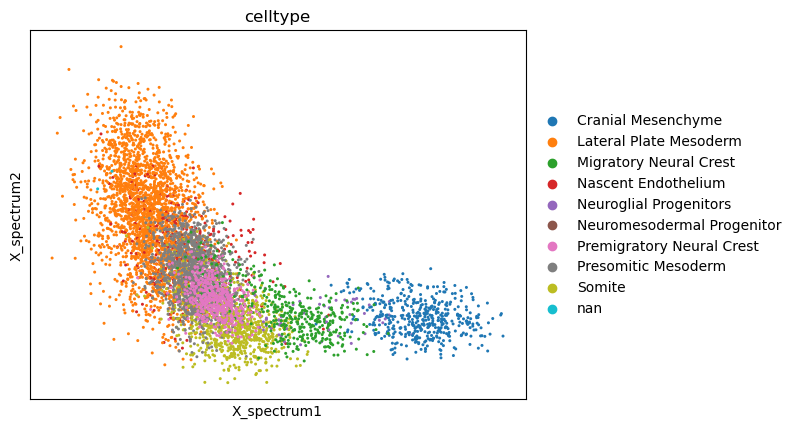

In [8]:
sc.pl.embedding(adata, 'X_spectrum', color = 'celltype')

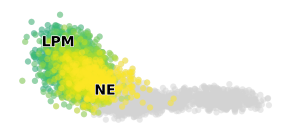

In [9]:
src = 'GSE162534'
adata_src = adata[adata.obs.source == src].copy()

fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_spectrum', size = 80, alpha = .5,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata_src, 'X_spectrum', size = 80, alpha = .5,
                color = 't', vmin = 0, colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata_src, 'X_spectrum', size = 80, alpha = 0,
                color = 'celltype', legend_loc = 'on data',
                legend_fontoutline = 1, frameon = False,
                show = False, ax = ax)
ax.set_title('')

label_dict = {
    'Lateral Plate Mesoderm' : 'LPM',
    'nan'                    : '',
    'Nascent Endothelium'    : 'NE'}

pos_dict = {
    'Lateral Plate Mesoderm' : (-.066, .25),
    'Nascent Endothelium'    : (.05, -.115)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, f'{src}.pdf')
plt.savefig(fn, bbox_inches = 'tight')

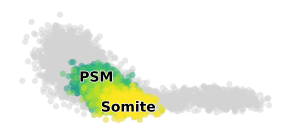

In [10]:
src = 'GSE229103'
adata_src = adata[adata.obs.source == src].copy()

fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_spectrum', size = 80, alpha = .5,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata_src, 'X_spectrum', size = 80, alpha = .5,
                color = 't', vmin = 0, colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata_src, 'X_spectrum', size = 80, alpha = 0,
                color = 'celltype', legend_loc = 'on data',
                legend_fontoutline = 1, frameon = False,
                show = False, ax = ax)
ax.set_title('')

label_dict = {
    'Neuromesodermal Progenitor' : '',
    'Presomitic Mesoderm'        : 'PSM'}

pos_dict = {
    'Presomitic Mesoderm' : (-.015, .085),
    'Somite'              : (.033, -.066)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, f'{src}.pdf')
plt.savefig(fn, bbox_inches = 'tight')

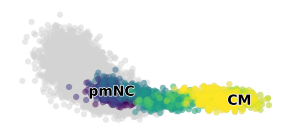

In [11]:
src = 'rRNAModifications'
adata_src = adata[adata.obs.source == src].copy()

fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata, 'X_spectrum', size = 80, alpha = .5,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata_src, 'X_spectrum', size = 80, alpha = .5,
                color = 't', vmin = 0, colorbar_loc = None,
                frameon = False, show = False, ax = ax)
sc.pl.embedding(adata_src, 'X_spectrum', size = 80, alpha = 0,
                color = 'celltype', legend_loc = 'on data',
                legend_fontoutline = 1, frameon = False,
                show = False, ax = ax)
ax.set_title('')

label_dict = {
    'Cranial Mesenchyme'        : 'CM',
    'Migratory Neural Crest'    : '',
    'Neuroglial Progenitors'    : '',
    'Premigratory Neural Crest' : 'pmNC'}

pos_dict = {
    'Cranial Mesenchyme'        : (.06, -.01),
    'Premigratory Neural Crest' : (0, .02)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, f'{src}.pdf')
plt.savefig(fn, bbox_inches = 'tight')